# 5 · In-silico experiments

The same cell, 45 different experiments: nutrients, oxygen, growth factors, death ligands, radiation, 26 drugs,
gene knock-outs. Each cell grows for 6 h, is perturbed, and is followed for 66 h. No experiment-specific
parameters exist: a drug is a list of inhibited proteins, a medium change is a concentration.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from humancell import plotting as P; P.style()
from humancell.cell import DRUGS
from humancell.experiments import run_many, treat, fate_table

E = {"untreated": treat("run", 0)}
E.update({"serum-free": treat("serum", 0.0), "no glucose": treat("set_medium", glucose=0.0), "no glutamine": treat("set_medium", glutamine=0.0),
          "no leucine": treat("set_medium", leucine=0.0), "hypoxia (1% O2)": treat("set_medium", O2=0.01), "anoxia": treat("set_medium", O2=0.0),
          "EGF (saturating)": treat("ligand", EGF=1.0), "TNF": treat("ligand", TNF=1.0), "TRAIL": treat("ligand", TNFSF10=1.0),
          "TNF + cycloheximide": [("run", (6,), {}), ("ligand", (), {"TNF": 1.0}), ("drug", ("cycloheximide",), {}), ("run", (66,), {})],
          "radiation 2 Gy": treat("irradiate", 2), "radiation 6 Gy": treat("irradiate", 6), "radiation 10 Gy": treat("irradiate", 10)})
for d in ["trametinib", "erlotinib", "alpelisib", "rapamycin", "torin1", "palbociclib", "RO3306", "nutlin3", "bortezomib", "cycloheximide",
          "actinomycinD", "oligomycin", "2DG", "methotrexate", "hydroxyurea", "simvastatin", "etoposide", "paclitaxel", "tunicamycin",
          "thapsigargin", "ouabain", "venetoclax", "S63845", "CB839", "H2O2"]:
    E[d] = treat("drug", d)
E["S63845 + navitoclax"] = [("run", (6,), {}), ("drug", ("S63845",), {}), ("drug", ("navitoclax",), {}), ("run", (66,), {})]
for gname in ["TP53", "RB1", "PTEN", "MYC", "MTOR", "POLR2A", "RPL3", "PCNA", "PLK1", "KIF23", "HMGCR"]:
    E[f"knock-out {gname}"] = treat("knockout", gname)
res = run_many(E, stochastic=False, met_interval=1800.0)
tab = fate_table(res)
pd.set_option("display.max_rows", 80)
tab

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,fate,hours,divisions,phase,growth_per_h,glucose_uptake,lactate_secretion,mTORC1,ISR,DSB
experiment,,,,,,,,,,
untreated,alive,72.0,3,G1,0.0295,0.65,1.05,0.99,0.01,0.9
serum-free,alive,72.0,0,G1,0.0303,0.65,1.05,0.92,0.08,1.0
no glucose,alive,72.0,1,G1,0.0119,-0.00,0.00,0.28,0.02,1.2
no glutamine,apoptosis,38.7,0,G1,-0.0042,0.65,1.05,0.00,1.00,1.1
no leucine,apoptosis,35.6,0,G1,-0.0071,0.65,1.05,0.00,1.00,1.0
hypoxia (1% O2),alive,72.0,3,G1,0.0292,0.65,1.05,0.93,0.02,1.9
anoxia,apoptosis,44.0,0,G1,-0.0054,0.86,1.27,0.92,0.58,1.0
EGF (saturating),alive,72.0,3,G1,0.0290,0.65,1.05,1.05,0.15,1.0
TNF,alive,72.0,3,S,0.0330,0.65,1.03,1.14,0.04,1.2


## Reading the table against known biology

| Experiment | Model | Known for HeLa / proliferating cells |
|---|---|---|
| serum withdrawal, MEK / EGFR / PI3K / mTOR inhibitors | G1 arrest or slowed growth, alive | cytostatic ✔ |
| palbociclib (CDK4/6) | **no effect** | HeLa is resistant: HPV E7 inactivates RB ✔ |
| nutlin-3 (MDM2) | **no effect** | HeLa is resistant: HPV E6 degrades p53 ✔ |
| TNF | survives | survives (NF-κB / c-FLIP) ✔ |
| TNF + cycloheximide | apoptosis within hours | the classic synergy: short-lived c-FLIP is lost ✔ |
| TRAIL, MCL-1 + BCL-xL inhibition | apoptosis | HeLa depends on MCL-1 and BCL-xL together ✔ |
| venetoclax (BCL-2 only) | survives | HeLa expresses little BCL-2 ✔ |
| paclitaxel, PLK1 loss | mitotic arrest then death | ✔ |
| hydroxyurea, PCNA loss | S-phase arrest | ✔ |
| RO-3306 (CDK1) | G2 arrest | ✔ |
| oligomycin | more glycolysis and lactate, slower growth | Pasteur-type shift ✔ |
| essential amino acid removed | growth stops, ISR on, later death | ✔ |
| ouabain | depolarisation, osmotic lysis | cytotoxic ✔ |
| methotrexate | **no effect** | should block growth ✘ (FBA finds a stoichiometric bypass) |
| no glucose | slow growth on amino acids | HeLa largely stops ✘/partly (FBA too permissive) |
| hypoxia 1% O₂ | redox stress, growth unchanged | mild slowing expected; HIF programme is weak in the model ✘/partly |

The two HeLa-specific resistances are not hard-coded outcomes: they follow from two cell-line traits
(`p53_extra_deg`, `rb_function`) acting through the p53 module and the G1 checkpoint. The next cell shows
this by repairing the lesions.

In [2]:
wt = {"p53_extra_deg": 0.0, "rb_function": 1.0}
E2 = {"HeLa + nutlin-3": treat("drug", "nutlin3"), "HeLa + palbociclib": treat("drug", "palbociclib"), "HeLa + 4 Gy": treat("irradiate", 4)}
for k, v in list(E2.items()):
    E2[k.replace("HeLa", "p53/RB-restored")] = [("init", (), {"traits": wt})] + v
E2["p53/RB-restored untreated"] = [("init", (), {"traits": wt}), ("run", (72,), {})]
res2 = run_many(E2, stochastic=False, met_interval=1800.0)
t2 = fate_table(res2)[["fate", "divisions", "phase"]]
t2["peak p53 (× basal)"] = [round(r["frame"].P53.max(), 1) for r in res2.values()]
t2["peak p21 protein (× start)"] = [round((r["frame"]["p:CDKN1A"] / r["frame"]["size"]).max() / (r["frame"]["p:CDKN1A"] / r["frame"]["size"]).iloc[0], 1) for r in res2.values()]
t2

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,fate,divisions,phase,peak p53 (× basal),peak p21 protein (× start)
experiment,,,,,
HeLa + nutlin-3,alive,3,G1,1.1,1.3
HeLa + palbociclib,alive,3,G1,1.1,1.2
HeLa + 4 Gy,alive,3,G1,1.1,1.4
p53/RB-restored + nutlin-3,alive,3,G1,2.9,1.4
p53/RB-restored + palbociclib,alive,0,G1,1.0,1.0
p53/RB-restored + 4 Gy,alive,3,G1,1.9,1.4
p53/RB-restored untreated,alive,3,G1,1.1,1.3


Restoring p53 and RB function makes the same cell sensitive to nutlin-3 and palbociclib and gives a p53/p21
response to radiation. Drug response here is a consequence of genotype, which is what a digital twin is for.

## Time courses

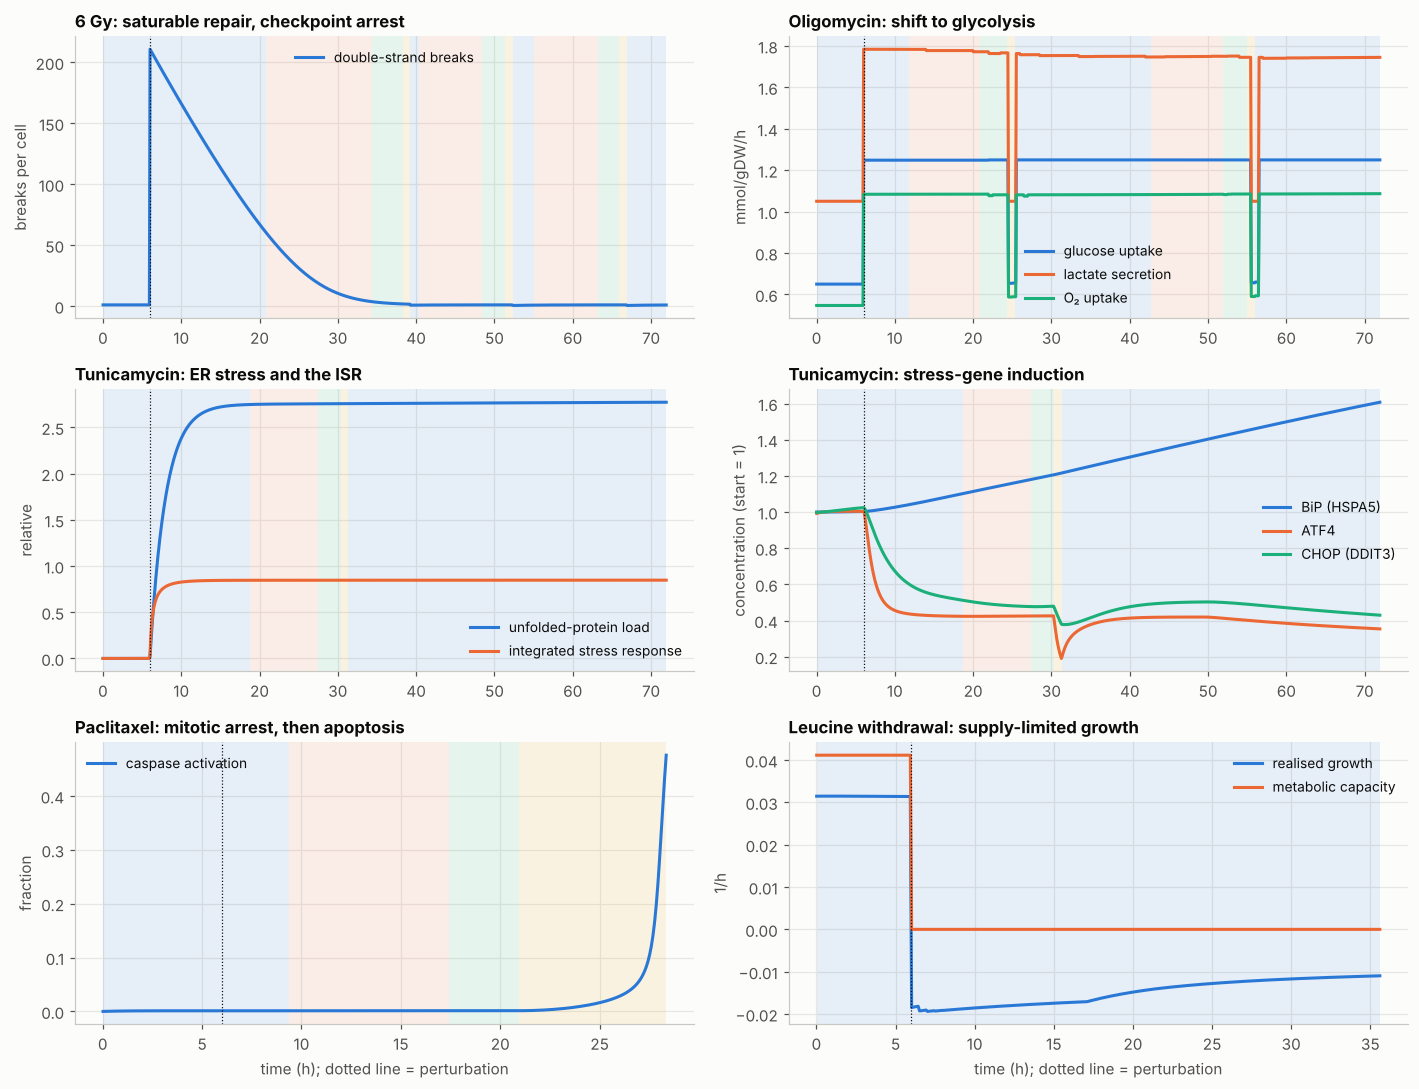

In [3]:
def course(ax, name, cols, labels, ylabel, title, norm=None):
    f = res[name]["frame"]; P.phase_bands(ax, f)
    for k, (c, lab) in enumerate(zip(cols, labels)):
        y = f[c] / f["size"] if c.startswith("p:") else f[c]
        if norm == "start": y = y / y.iloc[10]
        ax.plot(f.t, np.abs(y) if c.startswith("q_") else y, label=lab, color=P.SERIES[k])
    ax.axvline(6, color=P.INK, lw=0.8, ls=":"); ax.set_title(title); ax.set_ylabel(ylabel); ax.legend(loc="best")

fig, axes = plt.subplots(3, 2, figsize=(13, 10))
course(axes[0, 0], "radiation 6 Gy", ["D"], ["double-strand breaks"], "breaks per cell", "6 Gy: saturable repair, checkpoint arrest")
course(axes[0, 1], "oligomycin", ["q_glc", "q_lac", "q_o2"], ["glucose uptake", "lactate secretion", "O₂ uptake"], "mmol/gDW/h", "Oligomycin: shift to glycolysis")
course(axes[1, 0], "tunicamycin", ["U", "isr"], ["unfolded-protein load", "integrated stress response"], "relative", "Tunicamycin: ER stress and the ISR")
course(axes[1, 1], "tunicamycin", ["p:HSPA5", "p:ATF4", "p:DDIT3"], ["BiP (HSPA5)", "ATF4", "CHOP (DDIT3)"], "concentration (start = 1)", "Tunicamycin: stress-gene induction", norm="start")
course(axes[2, 0], "paclitaxel", ["C"], ["caspase activation"], "fraction", "Paclitaxel: mitotic arrest, then apoptosis")
course(axes[2, 1], "no leucine", ["mu", "mu_cap"], ["realised growth", "metabolic capacity"], "1/h", "Leucine withdrawal: supply-limited growth")
for ax in axes[-1]: ax.set_xlabel("time (h); dotted line = perturbation")
plt.tight_layout(); plt.show()

## Genome-wide transcriptional response
Every experiment yields a full transcriptome. Example: MEK inhibition, 24 h after treatment, against the
untreated cell at the same time point.

In [4]:
E3 = {"untreated": [("run", (30,), {})], "trametinib": [("run", (6,), {}), ("drug", ("trametinib",), {}), ("run", (24,), {})],
      "tunicamycin": [("run", (6,), {}), ("drug", ("tunicamycin",), {}), ("run", (24,), {})]}
r3 = run_many(E3, stochastic=False, want=("mrna",))
from humancell import data
g = data.build_gene_table("HeLa")
def lfc(name):
    a, b = r3[name]["mrna"] / r3[name]["summary"]["size"], r3["untreated"]["mrna"] / r3["untreated"]["summary"]["size"]
    ok = (g.mrna.values > 2)
    return pd.Series(np.log2((a[ok] + 0.5) / (b[ok] + 0.5)), index=g.symbol.values[ok]).sort_values()
out = {}
for name in ["trametinib", "tunicamycin"]:
    s = lfc(name)
    out[f"{name}: most repressed"] = [f"{k} ({v:+.2f})" for k, v in s.head(12).items()]
    out[f"{name}: most induced"] = [f"{k} ({v:+.2f})" for k, v in s.tail(12)[::-1].items()]
    print(f"{name}: {(s.abs() > 0.3).sum()} genes change by more than 1.23×")
pd.DataFrame(out)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


trametinib: 118 genes change by more than 1.23×
tunicamycin: 4751 genes change by more than 1.23×


,trametinib: most repressed,trametinib: most induced,tunicamycin: most repressed,tunicamycin: most induced
0,CDCA4 (-0.88),ETF1 (+0.47),ERP29 (-0.67),DNAJB9 (+2.07)
1,POLE3 (-0.83),MARCKS (+0.35),SIRT2 (-0.67),RTN3 (+1.97)
2,CDCA7 (-0.81),RHOBTB3 (+0.35),CHKA (-0.51),ATG5 (+1.74)
3,RACGAP1 (-0.78),CSNK2B (+0.34),MTOR (-0.49),IARS1 (+1.59)
4,GMNN (-0.77),RASIP1 (+0.33),RBM5 (-0.44),SERP1 (+1.59)
5,MCM6 (-0.73),MLLT3 (+0.28),CTDSPL2 (-0.42),LARS1 (+1.58)
6,FBXO5 (-0.73),IKBKG (+0.28),FNBP4 (-0.40),POLR2C (+1.58)
7,MT1G (-0.72),PPIA (+0.27),REXO4 (-0.37),SLC30A5 (+1.57)
8,FBN2 (-0.72),CFLAR (+0.26),MGA (-0.36),WBP1 (+1.57)
9,MCM10 (-0.69),CENPX (+0.25),COX7A2L (-0.36),YARS2 (+1.57)


MEK inhibition represses ERK-dependent immediate-early and proliferation genes; tunicamycin induces the
ATF4/ATF6/XBP1 programme. Fold changes are smaller than measured ones (typically 2–10× for the strongest
targets) because regulatory strengths are uniform rather than fitted. This is the model's main quantitative
weakness and the clearest place where perturbation data should be used to learn weights on the fixed topology.

## Dose–response

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


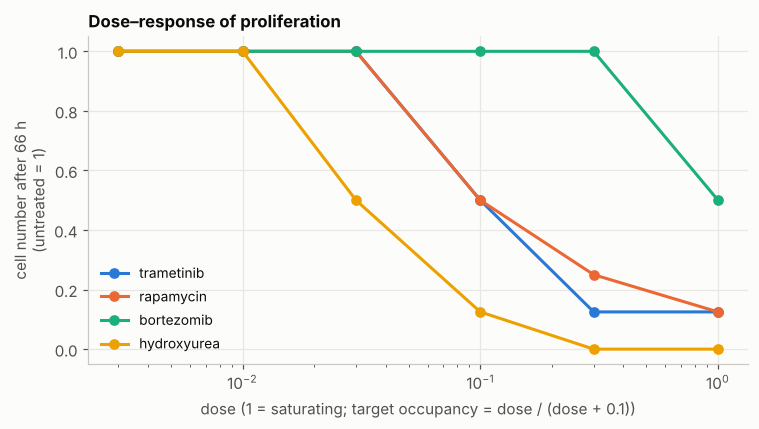

In [5]:
doses = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
E4 = {f"{d}@{x}": [("run", (6,), {}), ("drug", (d,), {"dose": x}), ("run", (66,), {})] for d in ["trametinib", "rapamycin", "bortezomib", "hydroxyurea"] for x in doses}
r4 = run_many(E4, stochastic=False, met_interval=1800.0)
base = 2.0 ** res["untreated"]["summary"]["divisions"]
fig, ax = plt.subplots(figsize=(7, 4))
for k, d in enumerate(["trametinib", "rapamycin", "bortezomib", "hydroxyurea"]):
    y = [(2.0 ** r4[f"{d}@{x}"]["summary"]["divisions"] if r4[f"{d}@{x}"]["summary"]["alive"] else 0.0) / base for x in doses]
    ax.plot(doses, y, marker="o", label=d, color=P.SERIES[k])
ax.set_xscale("log"); ax.set_xlabel("dose (1 = saturating; target occupancy = dose / (dose + 0.1))"); ax.set_ylabel("cell number after 66 h\n(untreated = 1)")
ax.set_title("Dose–response of proliferation"); ax.legend()
plt.tight_layout(); plt.show()

Doses are in units of target occupancy, not molar concentration: converting to µM needs each drug's binding
constant and cellular uptake, which the model does not contain.